# Weighted Coverage Exponential

Here, we weight some of the regions to have higher importance as compared to others based on the rated value  

In [1]:
import Pkg; Pkg.activate("../.."); Pkg.instantiate()

  Activating project at `~/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim`


In [2]:
using Logging: global_logger
using TerminalLoggers: TerminalLogger
global_logger(TerminalLogger())

using ProgressLogging

In [3]:
using Plots, Revise, StaticArrays, Interpolations, LinearAlgebra

In [4]:
include("../../src/kf.jl")
include("../../src/ngpkf.jl")
include("../../src/SyntheticData.jl")
include("../../src/ergodic.jl")
include("../../src/simulator_spatial.jl")
include("../../src/SOC_Controller.jl")

Main.SoCController

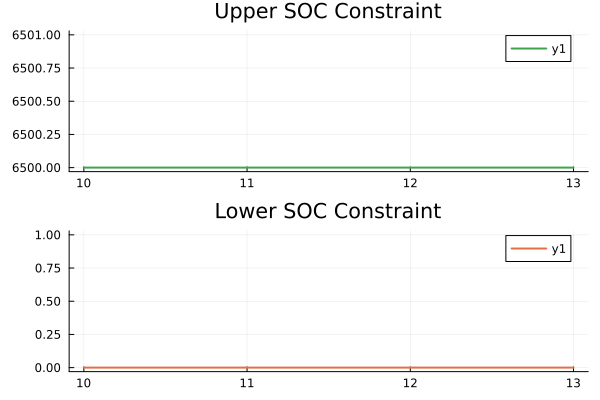

In [5]:
Δt = 0.1; # time step in hours
t = 10:Δt:13;
og_time = t;

lcbf = SoCController.compute_lcbf();
ucbf = SoCController.compute_ucbf();


l = @layout[a;b]
plot(
    plot(og_time, ucbf, title="Upper SOC Constraint", color=3, lw=2),
    plot(og_time, lcbf, title="Lower SOC Constraint", color=2, lw=2),
    layout=l,
)

# # plot(og_time, [ucbf, lcbf], layout=(2,1), label=false, title=["Upper Constraint", "Lower Constraint"])
# xlabel!("Mission Time [hr, 12 = noon]");
# ylabel!("State of Charge [Wh]");
# plot!(legend=false, dpi=1200)

In [6]:
b = SoCController.generate_SOC_target(lcbf, ucbf);

p2min: 0.000749374


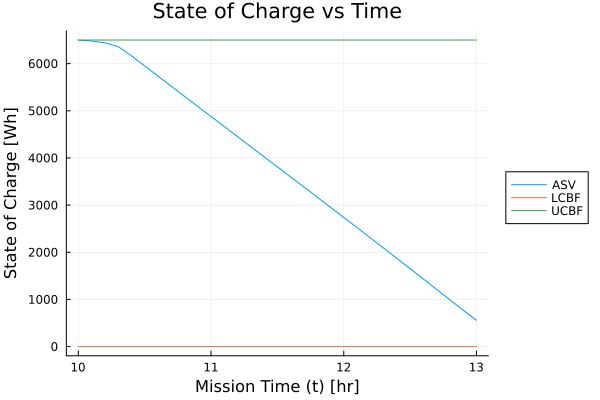

In [7]:
# Plot SOC vs Time
plot(og_time, b, label="ASV");
plot!(og_time, lcbf, label="LCBF");
plot!(og_time, ucbf, label="UCBF");
xlabel!("Mission Time (t) [hr]");
ylabel!("State of Charge [Wh]");
title!("State of Charge vs Time");
plot!(legend=:outerright)

In [8]:
v = SoCController.generate_vel_profile(lcbf, ucbf, b);

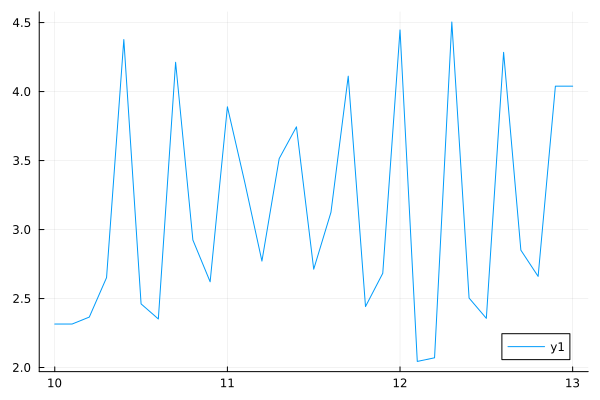

In [9]:
plot(og_time, v)

In [10]:
length(v)

31

In [11]:
# Get it in the right shape
v_interpolted = interpolate(v, BSpline(Linear()))
v_interpolted(31)

4.039159409514241

In [12]:
times = 0:6:180
v_itp = interpolate((times,), v, Gridded(Linear()))

31-element interpolate((0:6:180,), ::Vector{Float64}, Gridded(Linear())) with element type Float64:
 2.315000057220459
 2.315000057220459
 2.3655569890646664
 2.6516423906210207
 4.377031252876856
 2.4610943870384987
 2.3517842184661517
 4.212324185764679
 2.924352355664829
 2.621403889762538
 3.889748889208846
 3.345495694738535
 2.7713229422515417
 ⋮
 2.682981986546998
 4.446766553634708
 2.0441683909864254
 2.0705257169813436
 4.5042703220491935
 2.503454130405384
 2.356403846843797
 4.284485491398701
 2.850591128560417
 2.6603732398817432
 4.039159409514241
 4.039159409514241

In [13]:
v_itp(180.)

4.039159409514241

## Spatial-only Matern-12 Kernel

In [17]:
# Define domain vars
dim = 100; # number of data points along each axis in the domain (defining a square domain)
xstart, xstop = 0, 25; # x-axis start and end positions
ystart, ystop = 0, 10; # y-axis start and end positions

σ_sq = 1.0
λₓ = 1/(5.0) 

env_data = SyntheticData.matern12_spatial(dim, xstart, xstop, ystart, ystop, σ_sq, λₓ);
# heatmap(range(xstart, stop=xstop, length=dim), range(ystart, stop=ystop, length=dim), env_data; c = :vik)
# title!("Synthetic Data: σ² = $(σ_sq), λₓ = $(λₓ)")

In [18]:
plotly();
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
# plot!(clims=(-2,2))

In [19]:
# Create an ngpkf grid based on the data
# λₓ_wrong = 1/(2.5) 

σ_spatial = σ_sq
# l_spatial = 1/λₓ_wrong
l_spatial = 1/λₓ

res_factor = 0.4 #l_spatial / sqrt(2.0)

kern = NGPKF.MaternKernel(σ_spatial, l_spatial)

ngp_grid_x = range(extrema(env_data.X)..., step= res_factor )
ngp_grid_y = range(extrema(env_data.Y)..., step= res_factor )



# ngp_grid_x = range(extrema(env_data.X)..., length=10) # step= res_factor )
# ngp_grid_y = range(extrema(env_data.Y)..., length=10)# step= res_factor )

0.0:0.4:10.0

In [20]:
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

Main.NGPKF.NGPKFGrid{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{SVector{2, Float64}}, Hermitian{Float64, Matrix{Float64}}, Main.NGPKF.MaternKernel{Float64}}(0.0:0.4:24.8, 0.0:0.4:10.0, SVector{2, Float64}[[0.0, 0.0], [0.4, 0.0], [0.8, 0.0], [1.2, 0.0], [1.6, 0.0], [2.0, 0.0], [2.4, 0.0], [2.8, 0.0], [3.2, 0.0], [3.6, 0.0]  …  [21.2, 10.0], [21.6, 10.0], [22.0, 10.0], [22.4, 10.0], [22.8, 10.0], [23.2, 10.0], [23.6, 10.0], [24.0, 10.0], [24.4, 10.0], [24.8, 10.0]], Main.NGPKF.MaternKernel{Float64}(1.0, 5.0), [10.221468408218861 -5.359611588172402 … 8.996671573591833e-7 3.2167883955530496e-6; -5.359611588172402 14.078370726036614 … 1.9874550557233728e-7 8.996671571317452e-7; … ; 8.996671573591833e-7 1.9874550557233728e-7 … 14.078370726036683 -5.359611588172417; 3.2167883955530496e-6 8.996671571317452e-7 … -5.359611588172417 10.22146840821888])

In [21]:
size(ngp_grid_x), size(ngp_grid_y)

((63,), (26,))

In [22]:
@assert maximum(abs.(ngpkf_grid.invK)) < 10.0


LoadError: AssertionError: maximum(abs.(ngpkf_grid.invK)) < 10.0

In [23]:
maximum(abs.(ngpkf_grid.invK))


16.23201797380581

In [24]:
size(ngpkf_grid.invK')


(1638, 1638)

In [25]:
x0s = [@SVector[rand(ngpkf_grid.xs[2:(end-2)]), rand(ngpkf_grid.ys[2:(end-2)])] for i=1:1]


1-element Vector{SVector{2, Float64}}:
 [8.0, 8.0]

In [26]:
SimulatorSpatial.measure(0.0, x0s, env_data; σ_meas = 0.05)

1-element Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}:
 Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}(0.0, [8.0, 8.0], -1.3485035077300807)

In [27]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
scatter!(first.(x0s), last.(x0s), label = "")
title!("q_T= 0.95 for w_T = 1.5 | Rest = 0.0")
# plot!(clims=(-2,2))

In [28]:
ΔT = 5.0 / 60.0 # seconds
Tend = 1.0 # hours 
ts = 0.0:(ΔT):(Tend * 60)

0.0:0.08333333333333333:60.0

In [29]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(ΔT)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

DxS (generic function with 1 method)

In [30]:
using DifferentialEquations
using ForwardDiff

function clarity_prediction(t, q0, C, R, Q)

    k = C / sqrt(Q * R)
    
    q∞ = k / (1 + k)

    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
end

    
function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
    println("q0: $(q0)")
    println("qf: $(qf)")
    println("C: $(C)")
    println("R: $(R)")
    println("Q: $(Q)")
    
    if q0 >= qf
        return 0.0
    end

    k = C / sqrt(Q * R)
    println("k: $(k)")
    
    q∞ = k / (1 + k)
    println("q∞: $(q∞)")
    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    
        
    if qf >= q∞
        return tmax
    end

    t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
    println("t: $(t)")

    return min(t, tmax)
end

C = 1.0
R = 0.5
Q = 0.0
Clarity_decay(u,p,t) = (C^2 / R) * (1-u)^2 - Q * u^2

# k = (C^2 / R)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

k = (C^2 / R)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

function Clarity_delta_t(current_clarity, target_clarity)
    delta_t = (target_clarity - current_clarity) / ((target_clarity - 1) * k * (current_clarity - 1))
    return delta_t
end

function Clarity_delta_new(current_clarity, target_clarity)
    den = -target_clarity*k + k*current_clarity*target_clarity + k - k*current_clarity
    return delta_t = (target_clarity - current_clarity) / den
end

function Forward_Simulate_Clarity(current_clarity, target_clarity; fn::Function = Clarity)
    """
    Forward simulate for maximum 10 seconds
    Here for now I only consider the spatiostatic environment 
    """    
    tspan = (0.0, 10.0) # 10 is just chosen to be a huge value for this problem
    u0 = current_clarity
    prob = ODEProblem(fn, u0, tspan)
    condition(u, t, integrator) = u ≥ target_clarity
    affect!(integrator) = terminate!(integrator)
    cb = DiscreteCallback(condition, affect!)
    sol = solve(prob, Tsit5(), callback = cb);
    return sol.t[end]
    
end

Forward_Simulate_Clarity (generic function with 1 method)

In [31]:
# Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))

In [32]:
 δt = Forward_Simulate_Clarity(0.5, 0.9; fn = Clarity_decay)

4.941428437228555

In [33]:
using LinearAlgebra, StatsBase


# Controller for weighted 1 


function ergo_controller_weighted_1(t, xs, w_hat;
        ergo_grid,
        ergo_q_map,
        traj,
        umax=30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )
        
    target_q = 0.95

    # Set the rated value matrix
    
    Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
    
    w_rated = ones(Nx, Ny)
    w_rated *= 2.5

    
    Mean = reshape(KF.μ(w_hat), Nx, Ny)
    Std = reshape(KF.σ(w_hat), Nx, Ny)
    q_target_temp = zeros(size(Mean) )

    for i in CartesianIndices(Mean)
        if ( (Mean[i] - 3 * Std[i]) <= w_rated[i] <= (Mean[i] + 3 * Std[i]))
            q_target_temp[i] = 0.95
        else
            q_target_temp[i] = 0.0
        end
    end    

    # Get it in the right shape
    q_target_itp = linear_interpolation((ngpkf_grid.xs, ngpkf_grid.ys), q_target_temp, extrapolation_bc=Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     

#     println(q_target_weighted)
    
    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      
    
    # Only explore the right-hand side of the environment
    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
#             println("here in first cond")
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end
        
    u = [ErgodicController.controller_single_integrator(ergo_grid, x, traj, target_spatial_dist; umax=umax) for x in xs]
    
#     println(u)
    
    return u, q_target_temp

end

ergo_controllers_weighted_1 = [ergo_controller_weighted_1 for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller_weighted_1)}:
 ergo_controller_weighted_1 (generic function with 1 method)

In [34]:
# Controller for weighted 2

function ergo_controller_weighted_2(t, xs, Mean, w_rated_val;
        ergo_grid,
        ergo_q_map,
        traj,
        umax=30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )
        
    target_q = 0.95

    # Set the rated value matrix    
    Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
    w_rated = ones(Nx, Ny)
    w_rated *= w_rated_val
  
#   Compute the target matrix 
    lambda_param = 0.1
    delta = -lambda_param*((Mean - w_rated).^2)
    q_target_temp = target_q*(exp.(delta))    

    # Get it in the right shape
    q_target_itp = linear_interpolation((ngpkf_grid.xs, ngpkf_grid.ys), q_target_temp, extrapolation_bc=Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     

#     println(q_target_weighted)
    
    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      
    
    # Only explore the right-hand side of the environment
    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
#             println("here in first cond")
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end
        
    u = [ErgodicController.controller_single_integrator(ergo_grid, x, traj, target_spatial_dist; umax=umax, do_boundary_correction=true) for x in xs]
    
#     println(u)
    
    return u, q_target_temp

end

ergo_controllers_weighted_2 = [ergo_controller_weighted_2 for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller_weighted_2)}:
 ergo_controller_weighted_2 (generic function with 1 method)

In [35]:
ΔT = 5.0/60.0 # minutes
Tend = 0.1 # hours 
ts = 0.0:(ΔT):(170)
fuse_measurements_every_ΔT = 5.0 # minutes
recompute_controller_every_ΔT = 5.0 / 60.0 # minutes
σ_t = zeros(63, 26);

In [36]:
w_rated_val = -1.5
@time res_ergo_exp =  SimulatorSpatial.simulate_weighted_exp_SoC_spatial(ts, x0s, ergo_controller_weighted_2, w_rated_val, v_itp; 
    ngpkf_grid=ngpkf_grid, 
    EnvDataSpatial=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:03:37
Progress:   1%|▌                                        |  ETA: 0:02:11
Progress:   2%|▋                                        |  ETA: 0:01:43
Progress:   2%|▉                                        |  ETA: 0:01:29
Progress:   3%|█▏                                       |  ETA: 0:01:20


Inside prediction of NGP


Progress:   3%|█▍                                       |  ETA: 0:01:43
Progress:   4%|█▌                                       |  ETA: 0:01:34
Progress:   4%|█▊                                       |  ETA: 0:01:28
Progress:   5%|██                                       |  ETA: 0:01:23
Progress:   5%|██▎                                      |  ETA: 0:01:18


Inside prediction of NGP


Progress:   6%|██▍                                      |  ETA: 0:01:21
Progress:   6%|██▋                                      |  ETA: 0:01:17
Progress:   7%|██▉                                      |  ETA: 0:01:14
Progress:   8%|███▏                                     |  ETA: 0:01:12
Progress:   8%|███▍                                     |  ETA: 0:01:09


...

Inside prediction of NGP


Progress:  97%|███████████████████████████████████████▊ |  ETA: 0:00:01
Progress:  98%|████████████████████████████████████████ |  ETA: 0:00:01
Progress:  98%|████████████████████████████████████████▎|  ETA: 0:00:01
Progress:  99%|████████████████████████████████████████▌|  ETA: 0:00:01
Progress:  99%|████████████████████████████████████████▋|  ETA: 0:00:00
Progress: 100%|████████████████████████████████████████▉|  ETA: 0:00:00


 51.793401 seconds (1.66 G allocations: 47.396 GiB, 5.98% gc time, 6.83% compilation time)


Progress: 100%|█████████████████████████████████████████| Time: 0:00:49


Main.SimulatorSpatial.SimResultWeighted{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(0.0:0.08333333333333333:170.0, Vector{SVector{2, Float64}}[[[8.0, 8.0]], [[8.192187091035658, 7.983238014532102]], [[8.384954105689609, 7.975640634787854]], [[8.575981156162007, 7.948705377124519]], [[8.76122890130474, 7.894852660971035]], [[8.930818858663752, 7.80289566841178]], [[9.08236717620502, 7.683522515785297]], [[9.21833636939113, 7.546667773003424]], [[9.34213532937902, 7.398712848707236]], [[9.449742785961034, 7.23859577464727]]  …  [[6.97823267911177, 7.4854645188736475]], [[7.175260155015922, 7.338778658468528]], [[7.359789007272996, 7.17424235701907]], [[7.540

In [37]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo_exp.xs]
    y = [r[i][2] for r in res_ergo_exp.xs]
    plot!(x,y, linewidth=3, color=:black, label = "")
end
plot!()

title!("q_T= 0.95 for exponential weighted coverage")

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
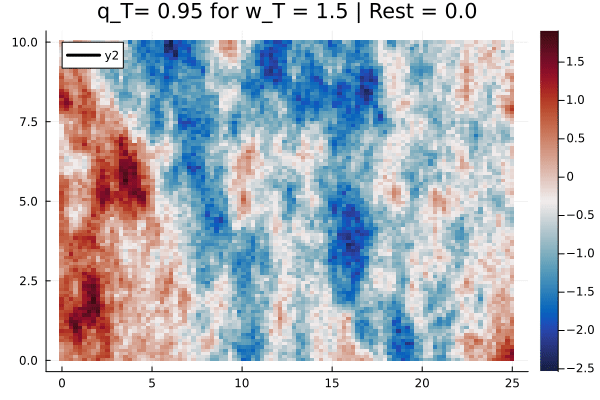

In [39]:
gr()
@gif for n = Int.(floor.(range(1, length(res_ergo_exp.xs), length=600)))
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo_exp.xs[1:n]]
        y = [r[i][2] for r in res_ergo_exp.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
    title!("q_T= 0.95 for w_T = 1.5 | Rest = 0.0")
end

In [40]:
u1 = Float64[]
u2 = Float64[]
speed = Float64[]

for i=1:length(res_ergo_exp.us)
    push!(u1, res_ergo_exp.us[i][1][1])
    push!(u2, res_ergo_exp.us[i][1][2])
    push!(speed, norm(res_ergo_exp.us[i][1]))
end

In [41]:
plot(speed)
ylims!(0., 5.0)

length(speed)
interpolated_times = range(0, stop=170, length=2041)
interpolated_speeds = [v_itp(t) for t in interpolated_times]

2041-element Vector{Float64}:
 2.315000057220459
 2.315000057220459
 2.315000057220459
 2.3150000572204594
 2.315000057220459
 2.315000057220459
 2.3150000572204585
 2.315000057220459
 2.315000057220459
 2.315000057220459
 2.315000057220459
 2.315000057220459
 2.315000057220459
 ⋮
 2.9093207427320578
 2.9284705506436155
 2.9476203585551803
 2.9667701664667447
 2.985919974378303
 3.0050697822898678
 3.024219590201432
 3.043369398112991
 3.0625192060245547
 3.0816690139361196
 3.100818821847678
 3.1199686297592426

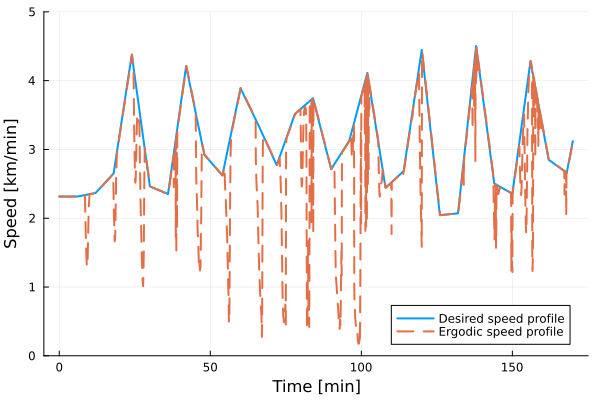

In [42]:
gr()
plot(interpolated_times, interpolated_speeds, lw=2.0, label="Desired speed profile")
plot!(interpolated_times, speed, linestyle=:dash, lw=2.0, label ="Ergodic speed profile")
ylims!(0., 5.0)
xlabel!("Time [min]")
ylabel!("Speed [km/min]")

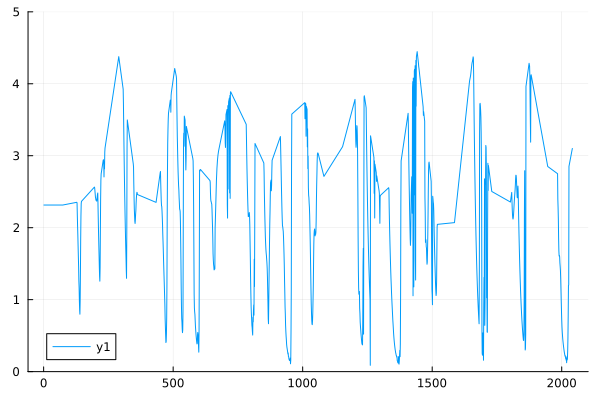

In [44]:
plot(speed)
ylims!(0., 5.0)

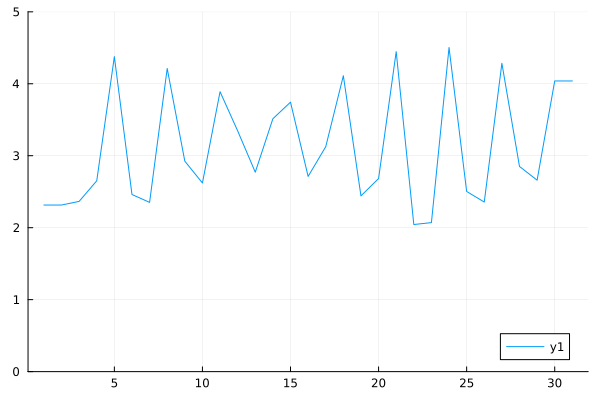

In [45]:
plot(v)
ylims!(0., 5.0)

In [43]:
target_maps_exp = [res_ergo_exp.q_target_maps[1],]

for i=2:63:length(res_ergo_exp.q_target_maps)
    push!(target_maps_exp,res_ergo_exp.q_target_maps[i])
end

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
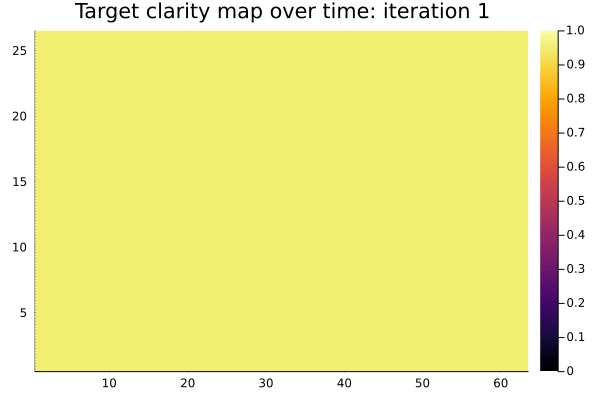

In [44]:
gr()
@gif for i=1:length(res_ergo_exp.q_target_maps)
    heatmap(res_ergo_exp.q_target_maps[i]', clims=(0, 1))
    title!("Target clarity map over time: iteration $i")
end

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
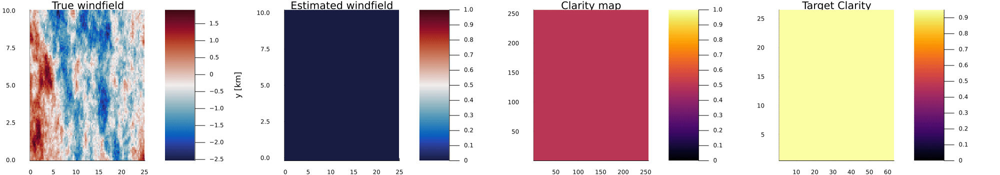

In [46]:
gr()
@gif for i=1:length(res_ergo_exp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[i],colormap=:balance, title = "Estimated windfield")
    p3 = heatmap(target_maps_exp[i]', title = "Target Clarity")
    p2 = heatmap(res_ergo_exp.ergo_q_maps[i]', clims=(0, 1), title = "Clarity map")
    plot(p0, p1, p2, p3, layout=@layout[a b c d], size=(2000, 350))
#     title!("Weighted coverage")
end

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
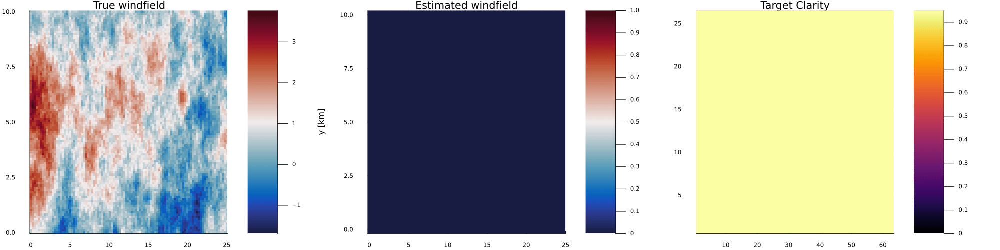

In [128]:
gr()
@gif for i=1:length(res_ergo.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[i],colormap=:balance, title = "Estimated windfield")
    p3 = heatmap(target_maps_exp[i]', title = "Target Clarity")
    plot(p0, p1, p3, layout=@layout[a b c], size=(2000, 500))
#     title!("Weighted coverage")
end

In [31]:
gr()

p1 = heatmap(ngpkf_grid, res_ergo.w_hats[end],colormap=:balance, clims=(-2,2), plot_min=true)
p2 = heatmap(ngpkf_grid, res_ergo.w_hats[end],colormap=:balance, clims=(-2,2), plot_max=true)
p3 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, clims=(-2, 2))
    
plot(p1, p3, p2, layout = (@layout [a;b; c]), size=[600, 600])

LoadError: UndefVarError: `res_ergo` not defined

In [32]:
# Compute RMSE

Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)

M = reshape(KF.μ(res_ergo.w_hats[end]), Nx, Ny)
heatmap(M',colormap=:balance, clims=(-2,2) )
x_new = 0:0.4:25
y_new = 0:0.4:10
Data_sampled = [env_data.itp_w(xi, yi) for yi in y_new, xi in x_new]
Diff = M' .- Data_sampled
rmse = sqrt(mean(Diff .^ 2))

LoadError: UndefVarError: `res_ergo` not defined

In [33]:
M'

LoadError: UndefVarError: `M` not defined

In [34]:
heatmap(Data_sampled,colormap=:balance, clims=(-2,2))

LoadError: UndefVarError: `Data_sampled` not defined

In [35]:
# Compute Precision

σ_prec = KF.σ(res_ergo.w_hats[end])
M_prec = reshape(σ_prec, Nx, Ny)
precision = sum(M_prec)/length(M_prec)

LoadError: UndefVarError: `res_ergo` not defined

In [261]:
using LinearAlgebra, StatsBase

mean_deficit_1 = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_ergo.ergo_q_maps]
mean_deficit_1[end]

0.20937851230359755

In [262]:
ts = range(1, 100, 20)
time = collect(ts)

20-element Vector{Float64}:
   1.0
   6.2105263157894735
  11.421052631578947
  16.63157894736842
  21.842105263157894
  27.05263157894737
  32.26315789473684
  37.473684210526315
  42.68421052631579
  47.89473684210526
  53.10526315789474
  58.31578947368421
  63.526315789473685
  68.73684210526316
  73.94736842105263
  79.15789473684211
  84.36842105263158
  89.57894736842105
  94.78947368421052
 100.0

In [263]:
# plot(res_ergo.w_hat_ts, mean_deficit_1, marker=:dot)
gr()
plot()
plot!(time, mean_deficit_1, marker=:dot)
ylabel!("Clarity Deficit[0,1]")
xlabel!("Time [min]")
ylims!(0., 0.6)

attempt to save state beyond implementation limit
attempt to save state beyond implementation limit
